Pre-processing step that allows to inspect the quality of the raw data. 

In [14]:
import sys
import types
import importlib.util
from pathlib import Path

# Make local src/preprocess.py importable as np2_pipeline.preprocess
pkg = sys.modules.get('np2_pipeline')
if pkg is None:
    pkg = types.ModuleType('np2_pipeline')
    pkg.__path__ = []
    sys.modules['np2_pipeline'] = pkg

preprocess_path = Path('../src/preprocess.py').resolve()
pre_spec = importlib.util.spec_from_file_location('np2_pipeline.preprocess', preprocess_path)
pre_mod = importlib.util.module_from_spec(pre_spec)
pre_spec.loader.exec_module(pre_mod)

sys.modules['np2_pipeline.preprocess'] = pre_mod
pkg.preprocess = pre_mod

In [16]:
import sys
import importlib.util
from pathlib import Path

# Load custom io module explicitly to avoid shadowing stdlib io
io_path = Path('../src/io.py').resolve()
spec = importlib.util.spec_from_file_location('custom_io', io_path)
custom_io = importlib.util.module_from_spec(spec)
spec.loader.exec_module(custom_io)
load_onix_recording = custom_io.load_onix_recording
load_ap_timestamps = custom_io.load_ap_timestamps

from np2_pipeline.preprocess import build_preprocessing_chain

import numpy as np
import matplotlib.pyplot as plt
import spikeinterface.full as si
import yaml

try:
    from IPython import get_ipython
    ip = get_ipython()
except Exception:
    ip = None

if ip is not None:
    try:
        ip.run_line_magic('autoreload', '2')
    except Exception:
        pass

    try:
        ip.run_line_magic('matplotlib', 'widget')
    except Exception:
        ip.run_line_magic('matplotlib', 'inline')

In [17]:
with open('../config.yml') as f:
    cfg = yaml.safe_load(f)

prb = cfg['probe']
acq = cfg['acquisition']
paths = cfg['paths']

In [18]:
recording = load_onix_recording(
    raw_dir=paths['raw_dir'],
    probe_name=prb['model'],
    sampling_frequency=acq['sampling_frequency'],
    n_channels=acq['n_channels'],
    dtype=acq['dtype'],
    gain_to_uV=acq['gain_to_uV'],
    offset_to_uV=acq['offset_to_uV'],
)

Found 1 chunk(s):
  NeuropixelsV2_ProbeA_AmplifierData_0.bin  (8.29 GB)

Recording loaded:
  Duration   : 360.0 s  (6.0 min)
  Channels   : 384
  Sampling   : 30000.0 Hz
  dtype      : uint16
  Probe      : Probe - 384ch


/media/rokas/8E3E49683E494A83/Users/Rokas/Documents/Code/AEON_OVC/src/io.py:124: RuntimeWarning: Could not download/load probe geometry from ProbeInterface (HTTPError: HTTP Error 404: Not Found). Using built-in NP2 fallback geometry instead.
  warnings.warn(


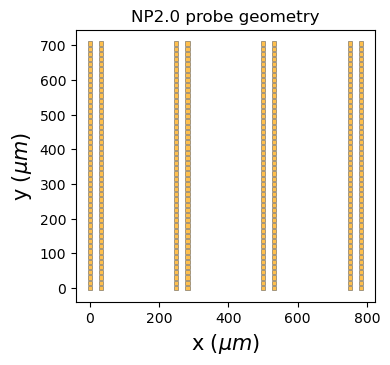

In [19]:
fig, ax = plt.subplots(figsize=(4, 10))
si.plot_probe_map(recording, ax=ax, with_channel_ids=False)
ax.set_title('NP2.0 probe geometry')
plt.tight_layout() #TODO: color the used channels from the channel map data in the future

In [6]:
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display

t_start = 60.0  # seconds into session
t_end = t_start + 0.2
all_ch_ids = list(recording.channel_ids[200:230])  # channels near middle of shank

fs = recording.get_sampling_frequency()
start_frame = int(t_start * fs)
end_frame = int(t_end * fs)

traces = recording.get_traces(
    start_frame=start_frame,
    end_frame=end_frame,
    channel_ids=all_ch_ids,
    return_in_uV=False,
    )

time_s = np.arange(start_frame, end_frame) / fs
time_ms = (time_s - t_start) * 1e3

# stack channels with offset so all traces are visible
offset = 1500.0

channel_picker = widgets.SelectMultiple(
    options=all_ch_ids,
    value=tuple(all_ch_ids[:8]),
    description='Channels',
    rows=min(12, len(all_ch_ids)),
    layout=widgets.Layout(width='250px', height='280px'),
)

plot_widget = go.FigureWidget()
plot_widget.update_layout(
    title='Zoomable raw traces (interactive, selectable channels)',
    xaxis_title='Time from t_start (ms)',
    template='plotly_white',
    height=700,
    dragmode='zoom',
)
plot_widget.update_xaxes(rangeslider_visible=True)
plot_widget.update_yaxes(showticklabels=False, ticks='', showgrid=False, zeroline=False)

index_map = {ch: i for i, ch in enumerate(all_ch_ids)}

def redraw(*_):
    selected = channel_picker.value
    with plot_widget.batch_update():
        plot_widget.data = []
        if len(selected) == 0:
            plot_widget.layout.annotations = [dict(
                text='Select at least one channel',
                showarrow=False,
                x=0.5, y=0.5, xref='paper', yref='paper'
            )]
            return
        plot_widget.layout.annotations = []

        for stack_i, ch in enumerate(selected):
            i = index_map[ch]
            y = traces[:, i] + stack_i * offset
            plot_widget.add_trace(
                go.Scattergl(
                    x=time_ms,
                    y=y,
                    mode='lines',
                    line=dict(width=1),
                    name=str(ch),
                    hovertemplate='ch %{text}<br>t=%{x:.2f} ms<br>value=%{y:.1f}<extra></extra>',
                    text=[str(ch)] * len(time_ms),
                    showlegend=False,
                )
            )

channel_picker.unobserve_all()
channel_picker.observe(redraw, names='value')
redraw()

display(widgets.HBox([channel_picker, plot_widget]))

noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

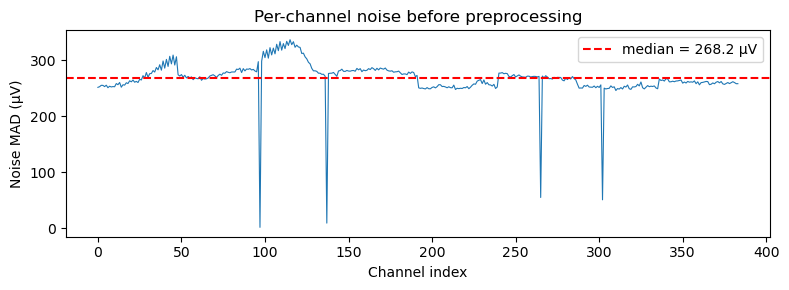

In [7]:
noise_uV = si.get_noise_levels(recording, method="std", return_in_uV=True)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(noise_uV, lw=0.8)
ax.axhline(np.median(noise_uV), color='r', linestyle='--', label=f'median = {np.median(noise_uV):.1f} µV')
ax.set_xlabel('Channel index')
ax.set_ylabel('Noise MAD (µV)')
ax.legend()
ax.set_title('Per-channel noise before preprocessing')
plt.tight_layout()

In [8]:
pre = cfg['preprocessing']
rec_preprocessed, bad_ch = build_preprocessing_chain(
    recording,
    highpass_freq_min=pre['highpass_freq_min'],
    bad_channel_score_threshold=pre['bad_channel_score_threshold'],
    artifact_removal=pre['artifact_removal'],
)
print(f'Bad channels: {bad_ch}')

Building preprocessing chain (lazy — no disk writes yet)
[0] Converted unsigned recording to signed dtype
[1] High-pass filter: cutoff = 300 Hz
[2] Phase shift correction is skipped for now (spikeinterface.preprocessing.phase_shift is not yet available)


/home/rokas/anaconda3/envs/np2_pipeline/lib/python3.11/site-packages/spikeinterface/preprocessing/detect_bad_channels.py:467: RuntimeWarning: invalid value encountered in divide
  xcorr = raw.T @ ref / np.sum(ref**2)


[3] Bad channels detected: 4
    Label counts: {np.str_('good'): 380, np.str_('dead'): 2, np.str_('noise'): 2}
    Bad channel IDs: [np.int64(97), np.int64(137), np.int64(252), np.int64(325)]
    Interpolated 4 bad channels from spatial neighbours
[4] Spatial artefact removal: local CAR (annulus 50.0–100.0 µm)

Preprocessing chain built (lazy). Call .save() or pass to run_sorter() to execute.
Bad channels: [np.int64(97), np.int64(137), np.int64(252), np.int64(325)]


noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

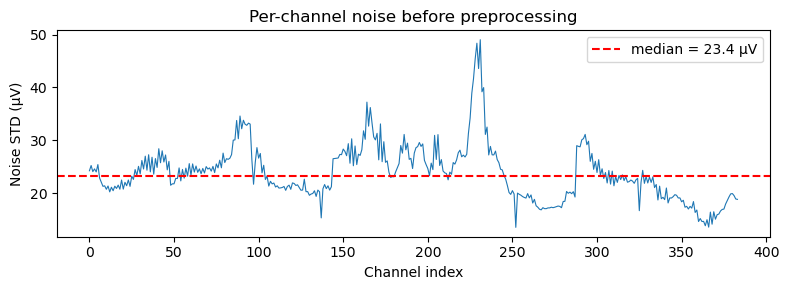

In [9]:
noise_uV = si.get_noise_levels(rec_preprocessed, method="std", return_in_uV=True)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(noise_uV, lw=0.8)
ax.axhline(np.median(noise_uV), color='r', linestyle='--', label=f'median = {np.median(noise_uV):.1f} µV')
ax.set_xlabel('Channel index')
ax.set_ylabel('Noise STD (µV)')
ax.legend()
ax.set_title('Per-channel noise before preprocessing')
plt.tight_layout()

  NeuropixelsV2_ProbeA_Clock_0.bin: 10,800,000 samples  (360.0 s)

Clock file loaded: 10,800,000 samples total
  Implied clock rate : 249,423,948 Hz  (expected ~249,423,527 Hz)
  Sample-0 HubClock  : 49,244,588  <- use as ap_sample0_hub_clock


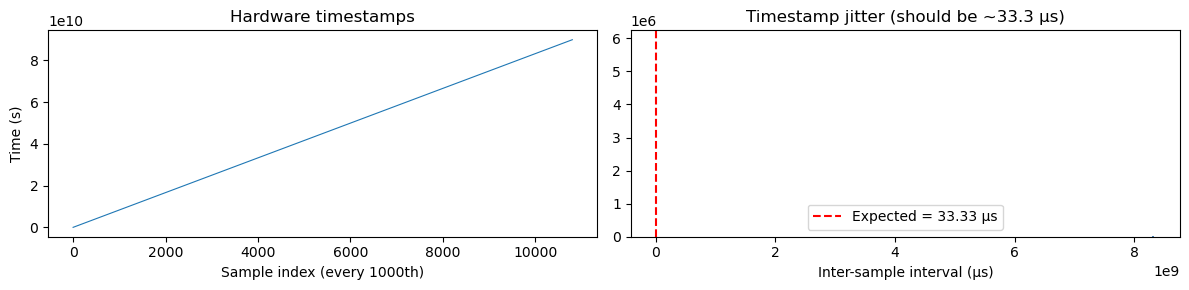

In [21]:
times = load_ap_timestamps(paths['raw_dir'])

# Check for gaps: inter-sample interval should be ~33.33 µs at 30 kHz
diffs_us = np.diff(times) * 1e6
expected_us = 1e6 / acq['sampling_frequency']

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].plot(times[::1000], lw=0.8)
axes[0].set_xlabel('Sample index (every 1000th)')
axes[0].set_ylabel('Time (s)')
axes[0].set_title('Hardware timestamps')

axes[1].hist(diffs_us, bins=50, color='steelblue')
axes[1].axvline(expected_us, color='r', linestyle='--',
                label=f'Expected = {expected_us:.2f} µs')
axes[1].set_xlabel('Inter-sample interval (µs)')
axes[1].set_title('Timestamp jitter (should be ~33.3 µs)')
axes[1].legend()
plt.tight_layout()

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import spikeinterface.full as si
# import spikeinterface.toolkit as st

rec = si.load('/media/rokas/Data/Temp/Ephys/Results/np2_scratch/2025-03-26_001/processed/preprocessed_binary')

rec_clean = si.notch_filter(rec, freq=13700, q=10)
rec_filtered = si.bandpass_filter(rec, freq_min=300, freq_max=6000)

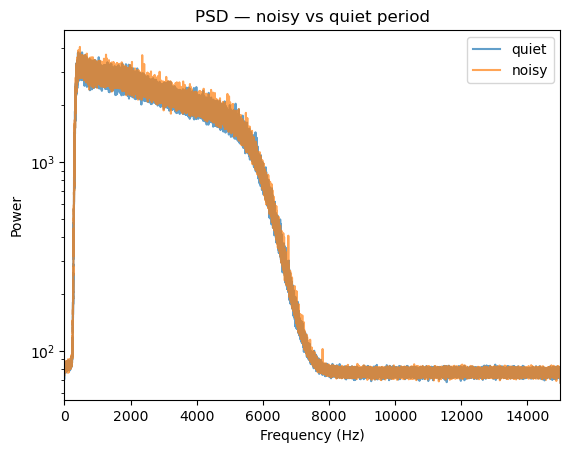

In [33]:
# Look at the power spectrum of a noisy vs quiet period
# First find a noisy timepoint by eye in the exploration notebook
t_noisy = 53879.0   # seconds — replace with your noisy timepoint
t_quiet = 53882.5

for label, t in [("quiet", t_quiet), ("noisy", t_noisy)]:
    traces = rec_filtered.get_traces(
        start_frame=int(t * 30000),
        end_frame=int((t + 3) * 30000)
    )
    freqs = np.fft.rfftfreq(traces.shape[0], d=1/30000)
    psd = np.abs(np.fft.rfft(traces, axis=0)).mean(axis=1)
    plt.semilogy(freqs, psd, label=label, alpha=0.7)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.legend()
plt.xlim(0, 15000)
plt.title("PSD — noisy vs quiet period")
plt.savefig("noise_psd.png", dpi=150)

/tmp/ipykernel_286292/2596675630.py:1: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  traces_noisy = rec.get_traces(


Text(0.5, 1.0, 'Channel correlation during noisy epoch')

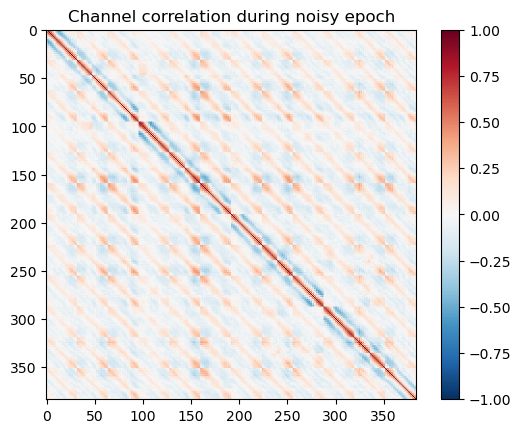

In [34]:
traces_noisy = rec.get_traces(
    start_frame=int(t_noisy * 30000),
    end_frame=int((t_noisy + 0.1) * 30000),
    return_scaled=True
)
corr = np.corrcoef(traces_noisy.T)
plt.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
plt.colorbar()
plt.title("Channel correlation during noisy epoch")

/tmp/ipykernel_286292/3130762872.py:1: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  traces_quiet = rec.get_traces(


Text(0.5, 1.0, 'Channel correlation during quiet epoch')

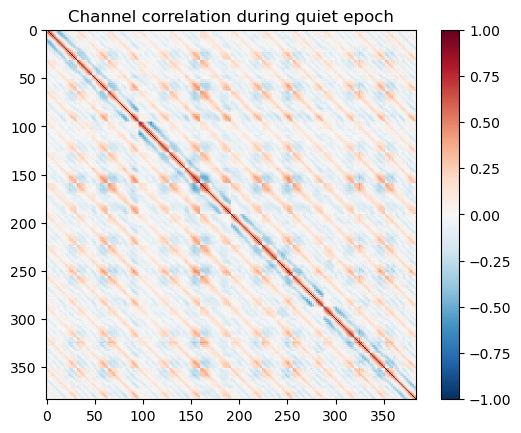

In [35]:
traces_quiet = rec.get_traces(
    start_frame=int(t_quiet * 30000),
    end_frame=int((t_quiet + 0.1) * 30000),
    return_scaled=True
)
corr = np.corrcoef(traces_quiet.T)
plt.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
plt.colorbar()
plt.title("Channel correlation during quiet epoch")

: 

In [ ]:
from pathlib import Path

meta_path = Path(r"/run/user/1000/gvfs/smb-share:server=ceph-gw02.hpc.swc.ucl.ac.uk,share=branco/Rokas/Ephys/SvyPrb_2026-03-23T11.17.45_g0/SvyPrb_2026-03-23T11.17.45_g0_t0.imec0.ap.meta")

def parse_value(v: str):
    v = v.strip()
    if "," in v:
        return [parse_value(x) for x in v.split(",")]
    try:
        return int(v)
    except ValueError:
        try:
            return float(v)
        except ValueError:
            return v

meta = {}
with meta_path.open("r", encoding="utf-8", errors="ignore") as f:
    for line in f:
        line = line.strip()
        if not line or "=" not in line:
            continue
        k, v = line.split("=", 1)
        meta[k.strip()] = parse_value(v)

# inspect a few common parameters
keys = [
    "imSampRate", "nSavedChans", "fileSizeBytes",
    "imDatPrb_type", "snsApLfSy", "imAiRangeMax", "imAiRangeMin", "imAiRange", "imMaxInt", "imChan0apGain"
]
for k in keys:
    print(f"{k}: {meta.get(k)}")

SyntaxError: invalid syntax (2744713083.py, line 28)

In [19]:
phase_shifted_recording = si.phase_shift(recording)

AssertionError: 'inter_sample_shift' is not a property!